## 1. Dataset Preparation


In [2]:

!pip -q install datasets scikit-learn pandas matplotlib seaborn


In [3]:

from datasets import load_dataset

dataset = load_dataset(
    "parquet",
    data_files="https://huggingface.co/datasets/Hello-SimpleAI/HC3/resolve/refs%2Fconvert%2Fparquet/all/train/0000.parquet",
    split="train"
)

print("Number of records:", len(dataset))
print("Columns:", dataset.column_names)
print("First record:", dataset[0])


all/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 39.3MB            

all/train/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Number of records: 24322
Columns: ['id', 'question', 'human_answers', 'chatgpt_answers', 'source']
First record: {'id': '0', 'question': 'Why is every book I hear about a " NY Times # 1 Best Seller " ? ELI5 : Why is every book I hear about a " NY Times # 1 Best Seller " ? Should n\'t there only be one " # 1 " best seller ? Please explain like I\'m five.', 'human_answers': ['Basically there are many categories of " Best Seller " . Replace " Best Seller " by something like " Oscars " and every " best seller " book is basically an " oscar - winning " book . May not have won the " Best film " , but even if you won the best director or best script , you \'re still an " oscar - winning " film . Same thing for best sellers . Also , IIRC the rankings change every week or something like that . Some you might not be best seller one week , but you may be the next week . I guess even if you do n\'t stay there for long , you still achieved the status . Hence , # 1 best seller .', "If you 're hearin

In [4]:

import pandas as pd

rows = []

for i, record in enumerate(dataset):
    human = record["human_answers"]
    ai = record["chatgpt_answers"]

    if human and ai and human[0] and ai[0]:
        rows.append({
            "question_id": i,
            "text": human[0],
            "label": 0
        })

        rows.append({
            "question_id": i,
            "text": ai[0],
            "label": 1
        })

df = pd.DataFrame(rows)

print("Total samples:", len(df))
print(df["label"].value_counts())
df.head()


Total samples: 47730
label
0    23865
1    23865
Name: count, dtype: int64


,question_id,text,label
0,0,"Basically there are many categories of "" Best ...",0
1,0,There are many different best seller lists tha...,1
2,1,salt is good for not dying in car crashes and ...,0
3,1,Salt is used on roads to help melt ice and sno...,1
4,2,The way it works is that old TV stations got a...,0


In [5]:
#Check answers before cleaning
text_key = df["text"].fillna("").str.strip().str.casefold()
text_key = text_key.str.replace(r"\s+", " ", regex=True)

blank = text_key.eq("")
answers = df.loc[~blank, ["label"]].copy()
answers["text_key"] = text_key[~blank]

labels_per_text = answers.groupby("text_key")["label"].nunique()

print("Total answers:", len(df))
print("Blank answers:", blank.sum())
print("Repeated answers beyond the first copy:", answers["text_key"].duplicated().sum())
print("Distinct answers with both labels:", (labels_per_text > 1).sum())

Total answers: 47730
Blank answers: 0
Repeated answers beyond the first copy: 2163
Distinct answers with both labels: 0


In [6]:
#Keep complete question pairs with unique answers
seen_answers = set()
keep_ids = []

for question_id, pair in df.groupby("question_id", sort=False):
    pair_keys = set(text_key.loc[pair.index])

    if seen_answers.isdisjoint(pair_keys):
        keep_ids.append(question_id)
        seen_answers.update(pair_keys)

before = len(df)
df = df[df["question_id"].isin(keep_ids)].copy()

#Verify that every remaining answer is unique and each label has one row per pair
assert text_key.loc[df.index].is_unique
assert (df.groupby(["question_id", "label"]).size().unstack(fill_value=0) == 1).all().all()

print("Question pairs removed:", (before - len(df)) // 2)
print("Question pairs kept:", len(keep_ids))
print("Human answers kept:", (df["label"] == 0).sum())
print("AI answers kept:", (df["label"] == 1).sum())

Question pairs removed: 1652
Question pairs kept: 22213
Human answers kept: 22213
AI answers kept: 22213


In [7]:

from sklearn.model_selection import GroupShuffleSplit

# Select 2,500 question-answer pairs
pairs = df["question_id"].drop_duplicates().sample(
    n=2500,
    random_state=42
)

sample_df = df[df["question_id"].isin(pairs)].copy()

# Keep answers from the same question together
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        sample_df,
        groups=sample_df["question_id"]
    )
)

train_df = sample_df.iloc[train_idx]
test_df = sample_df.iloc[test_idx]

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))


Training samples: 4000
Testing samples: 1000


In [8]:
#Starts from the training rows
training_pool = sample_df.iloc[train_idx]

#Chooses 250 question IDs so both answers to each question stay together.
question_ids = training_pool["question_id"].drop_duplicates()
validation_ids = question_ids.sample(n=250, random_state=42)
in_validation = training_pool["question_id"].isin(validation_ids)

validation_df = training_pool.loc[in_validation].copy()
train_df = training_pool.loc[~in_validation].copy()

#Checks that each question ID belongs to only one split.
train_questions = set(train_df["question_id"])
validation_questions = set(validation_df["question_id"])
test_questions = set(test_df["question_id"])

assert train_questions.isdisjoint(validation_questions)
assert train_questions.isdisjoint(test_questions)
assert validation_questions.isdisjoint(test_questions)

print("Training samples:", len(train_df))
print("Validation samples:", len(validation_df))
print("Testing samples:", len(test_df))

Training samples: 3500
Validation samples: 500
Testing samples: 1000


In [9]:
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

splits = {"train": train_df, "validation": validation_df, "test": test_df}
columns = ["question_id", "text", "label"]
zip_name = "Member_2_Dataset.zip"

with ZipFile(zip_name, "w", compression=ZIP_DEFLATED) as bundle:
    for name, data in splits.items():
        filename = f"{name}.csv"
        data[columns].to_csv(filename, index=False)
        bundle.write(filename)

        human = (data["label"] == 0).sum()
        ai = (data["label"] == 1).sum()
        print(f"{filename}: {human} human, {ai} AI")

files.download(zip_name)

train.csv: 1750 human, 1750 AI
validation.csv: 250 human, 250 AI
test.csv: 500 human, 500 AI


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##2. Load the Prepared Dataset



In [62]:

import zipfile
import os

dataset_zip = "/content/Member_2_Dataset.zip"

with zipfile.ZipFile(dataset_zip, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Dataset extracted successfully!")


Dataset extracted successfully!


In [11]:

import pandas as pd
import os

# Find all extracted CSV files
for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))


/content/validation.csv
/content/train.csv
/content/test.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv


In [31]:

import pandas as pd

train_df = pd.read_csv("/content/train.csv")
val_df = pd.read_csv("/content/validation.csv")
test_df = pd.read_csv("/content/test.csv")

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nColumn names:", train_df.columns.tolist())
print("\nFirst 3 rows:")
display(train_df.head(3))


Training samples: 3500
Validation samples: 500
Testing samples: 1000

Column names: ['question_id', 'text', 'label']

First 3 rows:


,question_id,text,label
0,17,> Will we eventually have to pay it off ? What...,0
1,17,"It's important for countries, just like people...",1
2,34,"Yes , but the reason why it is darker is due t...",0


In [32]:

# Separate text and labels for each dataset

X_train = train_df["text"].fillna("")
y_train = train_df["label"]

X_val = val_df["text"].fillna("")
y_val = val_df["label"]

X_test = test_df["text"].fillna("")
y_test = test_df["label"]

# Check the shapes and class distribution
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nTraining label distribution:")
print(y_train.value_counts())


Training: (3500,) (3500,)
Validation: (500,) (500,)
Testing: (1000,) (1000,)

Training label distribution:
label
0    1750
1    1750
Name: count, dtype: int64


##3. Logistic Regression

In [33]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline
import time

# Create the TF-IDF + Logistic Regression pipeline
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        stop_words="english"
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
start_time = time.time()
lr_model.fit(X_train, y_train)
lr_training_time = time.time() - start_time

# Evaluate on validation and test datasets
lr_val_pred = lr_model.predict(X_val)
lr_test_pred = lr_model.predict(X_test)

print("Logistic Regression Results")
print("-" * 35)
print(f"Validation accuracy: {accuracy_score(y_val, lr_val_pred):.4f}")
print(f"Test accuracy: {accuracy_score(y_test, lr_test_pred):.4f}")
print(f"Training time: {lr_training_time:.3f} seconds")

print("\nClassification Report:")
print(classification_report(y_test, lr_test_pred))


Logistic Regression Results
-----------------------------------
Validation accuracy: 0.9020
Test accuracy: 0.9000
Training time: 2.474 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.90      0.90       500
           1       0.90      0.90      0.90       500

    accuracy                           0.90      1000
   macro avg       0.90      0.90      0.90      1000
weighted avg       0.90      0.90      0.90      1000



##4. Naive Bayes

In [34]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
import time

# TF-IDF + Naive Bayes
nb_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        stop_words="english"
    )),
    ("classifier", MultinomialNB())
])

# Train the model
start_time = time.time()
nb_model.fit(X_train, y_train)
nb_training_time = time.time() - start_time

# Evaluate
nb_val_pred = nb_model.predict(X_val)
nb_test_pred = nb_model.predict(X_test)

print("Naive Bayes Results")
print("-" * 35)
print(f"Validation accuracy: {accuracy_score(y_val, nb_val_pred):.4f}")
print(f"Test accuracy: {accuracy_score(y_test, nb_test_pred):.4f}")
print(f"Training time: {nb_training_time:.3f} seconds")

print("\nClassification Report:")
print(classification_report(y_test, nb_test_pred))


Naive Bayes Results
-----------------------------------
Validation accuracy: 0.8680
Test accuracy: 0.8770
Training time: 1.502 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.87      0.88       500
           1       0.87      0.89      0.88       500

    accuracy                           0.88      1000
   macro avg       0.88      0.88      0.88      1000
weighted avg       0.88      0.88      0.88      1000



##5. Linear SVM

In [35]:

from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report
import time

# TF-IDF + Linear SVM
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        stop_words="english"
    )),
    ("classifier", LinearSVC(random_state=42))
])

# Train the model
start_time = time.time()
svm_model.fit(X_train, y_train)
svm_training_time = time.time() - start_time

# Evaluate using validation and test data
svm_val_pred = svm_model.predict(X_val)
svm_test_pred = svm_model.predict(X_test)

print("Linear SVM Results")
print("-" * 35)
print(f"Validation accuracy: {accuracy_score(y_val, svm_val_pred):.4f}")
print(f"Test accuracy: {accuracy_score(y_test, svm_test_pred):.4f}")
print(f"Training time: {svm_training_time:.3f} seconds")

print("\nClassification Report:")
print(classification_report(y_test, svm_test_pred))


Linear SVM Results
-----------------------------------
Validation accuracy: 0.9040
Test accuracy: 0.9140
Training time: 2.162 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.89      0.91       500
           1       0.89      0.94      0.92       500

    accuracy                           0.91      1000
   macro avg       0.92      0.91      0.91      1000
weighted avg       0.92      0.91      0.91      1000



## 6. Model Performance Comparison

In [36]:

import pandas as pd
from sklearn.metrics import accuracy_score

results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM"
    ],
    "Validation Accuracy": [
        accuracy_score(y_val, lr_val_pred),
        accuracy_score(y_val, nb_val_pred),
        accuracy_score(y_val, svm_val_pred)
    ],
    "Test Accuracy": [
        accuracy_score(y_test, lr_test_pred),
        accuracy_score(y_test, nb_test_pred),
        accuracy_score(y_test, svm_test_pred)
    ],
    "Training Time (s)": [
        lr_training_time,
        nb_training_time,
        svm_training_time
    ]
})

display(results_df)

results_df.to_csv(
    "/content/final_model_comparison.csv",
    index=False
)

print("Results saved successfully!")


,Model,Validation Accuracy,Test Accuracy,Training Time (s)
0,Logistic Regression,0.902,0.900,2.474494
1,Naive Bayes,0.868,0.877,1.502264
2,Linear SVM,0.904,0.914,2.162035


Results saved successfully!


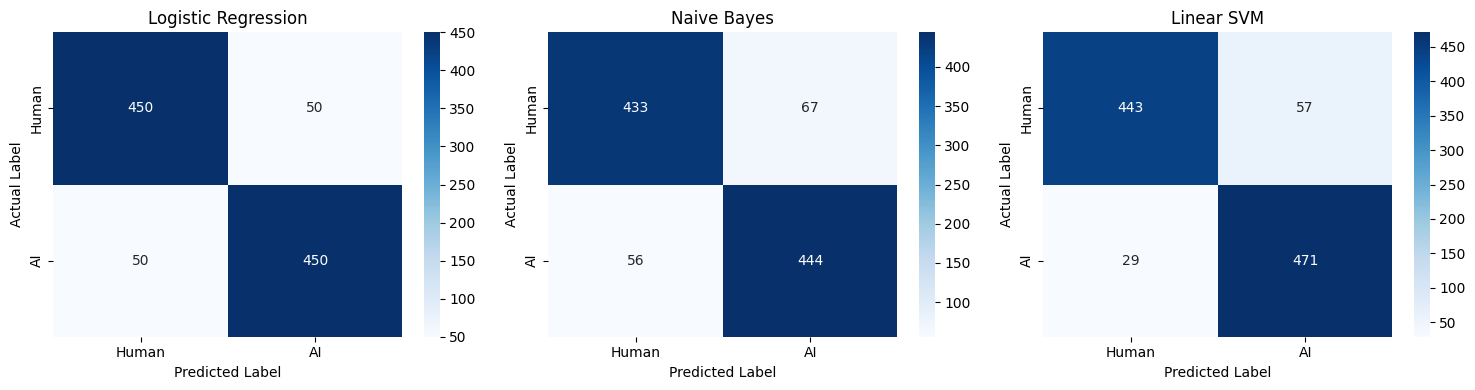

Confusion matrices saved!


In [37]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

models = [
    ("Logistic Regression", lr_test_pred),
    ("Naive Bayes", nb_test_pred),
    ("Linear SVM", svm_test_pred)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, predictions) in zip(axes, models):
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Human", "AI"],
        yticklabels=["Human", "AI"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    "/content/confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrices saved!")


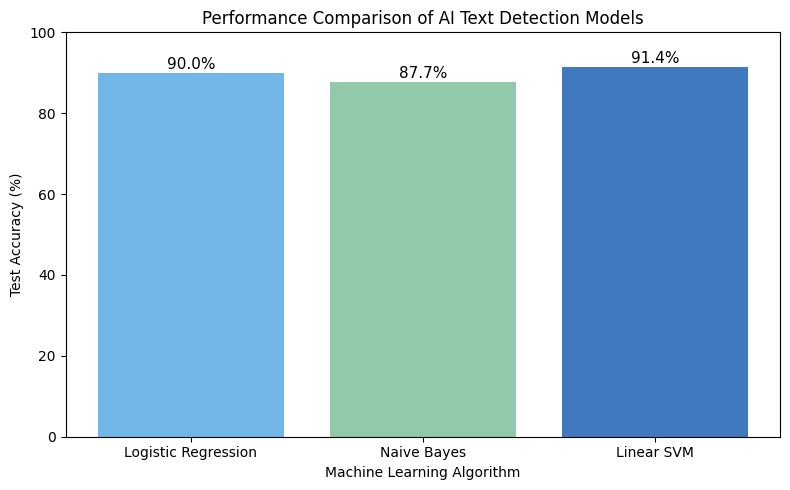

Accuracy comparison graph saved!


In [63]:

import matplotlib.pyplot as plt

models = ["Logistic Regression", "Naive Bayes", "Linear SVM"]
test_accuracy = [
    accuracy_score(y_test, lr_test_pred) * 100,
    accuracy_score(y_test, nb_test_pred) * 100,
    accuracy_score(y_test, svm_test_pred) * 100
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    models,
    test_accuracy,
    color=["#70B7E8", "#92C9AA", "#4079BE"]
)

plt.ylim(0, 100)
plt.ylabel("Test Accuracy (%)")
plt.xlabel("Machine Learning Algorithm")
plt.title("Performance Comparison of AI Text Detection Models")

for bar, accuracy in zip(bars, test_accuracy):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.1f}%",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.savefig(
    "/content/model_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Accuracy comparison graph saved!")


## 7. Preliminary Logistic Regression and Error Analysis

In [40]:

import time
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=10000)),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Measure training time
start_time = time.time()

model.fit(train_df["text"], train_df["label"])

training_time = time.time() - start_time

# Make predictions
predictions = model.predict(test_df["text"])

# Display results
print("Accuracy:", accuracy_score(test_df["label"], predictions))
print("Training Time:", training_time, "seconds")

print(classification_report(
    test_df["label"],
    predictions,
    target_names=["Human", "AI"]
))



Accuracy: 0.921
Training Time: 0.5715582370758057 seconds
              precision    recall  f1-score   support

       Human       0.92      0.92      0.92       500
          AI       0.92      0.92      0.92       500

    accuracy                           0.92      1000
   macro avg       0.92      0.92      0.92      1000
weighted avg       0.92      0.92      0.92      1000



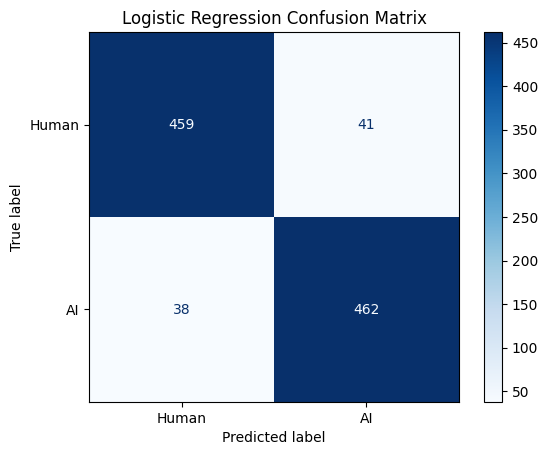

In [41]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(test_df["label"], predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Human", "AI"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression Confusion Matrix")
plt.savefig("baseline_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [42]:


import pandas as pd
from sklearn.metrics import accuracy_score

baseline_results = pd.DataFrame([{
    "Model": "TF-IDF + Logistic Regression",
    "Accuracy": accuracy_score(test_df["label"], predictions),
    "Training_Time_Seconds": training_time,
    "Training_Samples": len(train_df),
    "Testing_Samples": len(test_df)
}])

baseline_results.to_csv(
    "baseline_results_preliminary.csv",
    index=False
)

print(baseline_results)


                          Model  Accuracy  Training_Time_Seconds  \
0  TF-IDF + Logistic Regression     0.921               0.571558   

   Training_Samples  Testing_Samples  
0              3500             1000  


In [43]:

import joblib

joblib.dump(
    model,
    "logistic_regression_baseline.joblib"
)

print("Model saved successfully!")


Model saved successfully!


In [45]:

import pandas as pd

error_analysis = test_df.copy()
error_analysis["predicted_label"] = predictions

mistakes = error_analysis[
    error_analysis["label"] != error_analysis["predicted_label"]
]

print("Total incorrect predictions:", len(mistakes))

display(
    mistakes[["text", "label", "predicted_label"]].head(10)
)


Total incorrect predictions: 79


,text,label,predicted_label
2,Worst - case : A rogue AI takes over every int...,0,1
39,A rocket engine works by using fuel to create ...,1,0
49,If you opened a jar filled with oxygen in spac...,1,0
99,Retailers sell things for $19.99 instead of $2...,1,0
100,A game engine is nothing more than a bunch of ...,0,1
103,A tax write-off is a way for a person or busin...,1,0
120,The Illuminati is a conspiracy theory that a b...,0,1
143,Sure! I'd be happy to help. Relativity is a th...,1,0
163,Lips are pink because of the blood that flows ...,1,0
167,Sure! Slugging percentage is a statistic that ...,1,0


In [46]:

analysis_df = test_df.copy()

analysis_df["prediction"] = predictions

analysis_df["correct"] = (
    analysis_df["label"] == analysis_df["prediction"]
)

analysis_df["word_count"] = (
    analysis_df["text"].str.split().str.len()
)

analysis_df["length_group"] = pd.cut(
    analysis_df["word_count"],
    bins=[0, 50, 100, 200, float("inf")],
    labels=["1-50", "51-100", "101-200", "201+"]
)

length_results = analysis_df.groupby(
    "length_group",
    observed=True
).agg(
    samples=("correct", "count"),
    accuracy=("correct", "mean")
)

print(length_results)


              samples  accuracy
length_group                   
1-50              128  0.953125
51-100            162  0.882716
101-200           428  0.939252
201+              282  0.900709


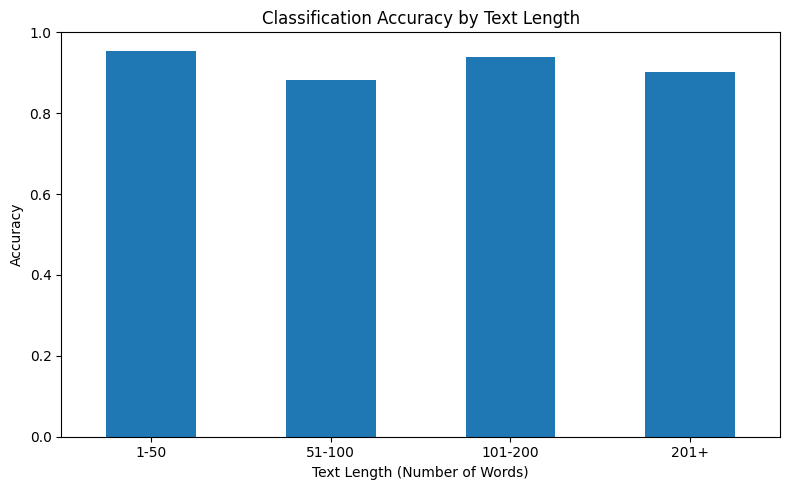

In [47]:

import matplotlib.pyplot as plt

length_results["accuracy"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Classification Accuracy by Text Length")
plt.xlabel("Text Length (Number of Words)")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "accuracy_by_text_length.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [48]:

length_results.to_csv("accuracy_by_text_length.csv")

from google.colab import files
files.download("accuracy_by_text_length.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. LSTM Deep Learning Model

In [49]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [51]:
splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

expected_sizes = {
    "train": 3500,
    "validation": 500,
    "test": 1000
}

text_keys = {}

for name, df in splits.items():
    # Check columns, sample counts, and missing values.
    assert {"question_id", "text", "label"}.issubset(df.columns)
    assert len(df) == expected_sizes[name], f"Unexpected {name} size"
    assert df["question_id"].notna().all()
    assert df["text"].notna().all()
    assert df["text"].map(lambda x: isinstance(x, str)).all()
    assert df["label"].isin([0, 1]).all()

    # Normalize text for duplicate checks without modifying the data.
    keys = (
        df["text"]
        .str.strip()
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
    )

    assert keys.ne("").all(), f"Blank text in {name}"
    assert keys.is_unique, f"Duplicate text in {name}"

    # Check label balance and complete human/AI question pairs.
    counts = df["label"].value_counts()
    assert counts.get(0, 0) == counts.get(1, 0), f"Unbalanced {name}"

    pair_counts = (
        df.groupby(["question_id", "label"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=[0, 1], fill_value=0)
    )
    assert pair_counts.eq(1).all().all(), f"Incomplete pairs in {name}"

    text_keys[name] = set(keys)

    print(
        f"{name}: {len(df)} samples | "
        f"Human: {counts[0]} | AI: {counts[1]}"
    )

# Check that questions and texts do not overlap across splits.
for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    assert set(splits[a]["question_id"]).isdisjoint(
        splits[b]["question_id"]
    ), f"Question overlap: {a} / {b}"

    assert text_keys[a].isdisjoint(text_keys[b]), (
        f"Text overlap: {a} / {b}"
    )

print("\nAll dataset checks passed. Ready for LSTM preprocessing!")

train: 3500 samples | Human: 1750 | AI: 1750
validation: 500 samples | Human: 250 | AI: 250
test: 1000 samples | Human: 500 | AI: 500

All dataset checks passed. Ready for LSTM preprocessing!


In [52]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

# Set a seed for more reproducible results.
tf.keras.utils.set_random_seed(42)

MAX_TOKENS = 10000
SEQUENCE_LENGTH = 300

# Lowercase text, remove punctuation, and convert words to integer IDs.
vectorizer = TextVectorization(
    max_tokens=MAX_TOKENS,
    standardize="lower_and_strip_punctuation",
    split="whitespace",
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH
)

# Learn the vocabulary ONLY from training data.
training_text = tf.data.Dataset.from_tensor_slices(
    train_df["text"].to_numpy(dtype=str)
).batch(64)

vectorizer.adapt(training_text)

# Convert training and validation text into numerical sequences.
X_train = vectorizer(
    tf.constant(train_df["text"].tolist())
).numpy()

X_val = vectorizer(
    tf.constant(val_df["text"].tolist())
).numpy()

y_train = train_df["label"].to_numpy(dtype=np.float32)
y_val = val_df["label"].to_numpy(dtype=np.float32)

VOCAB_SIZE = len(vectorizer.get_vocabulary())

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Vocabulary size:", VOCAB_SIZE)
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("First 20 token IDs:", X_train[0][:20])

TensorFlow version: 2.21.0
Available GPUs: []
Vocabulary size: 10000
Training shape: (3500, 300)
Validation shape: (500, 300)
First 20 token IDs: [ 40  69 655  21   3 111  10 179  75  25  69  49  65   1  22 384   7  23
   2  89]


In [53]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dropout, Dense

tf.keras.utils.set_random_seed(42)

lstm_model = Sequential([
    Input(shape=(SEQUENCE_LENGTH,), dtype="int64"),

    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=64,
        mask_zero=True
    ),

    LSTM(64),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [54]:
import time
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "best_lstm.keras",
    monitor="val_loss",
    save_best_only=True
)

start_time = time.perf_counter()

history = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=32,
    callbacks=[early_stopping, checkpoint],
    shuffle=True,
    verbose=1
)

lstm_training_time = time.perf_counter() - start_time

best_epoch = int(np.argmin(history.history["val_loss"])) + 1

print(f"\nTraining time: {lstm_training_time:.2f} seconds")
print(f"Epochs completed: {len(history.history['loss'])}")
print(f"Best epoch by validation loss: {best_epoch}")
print(
    "Validation accuracy at best epoch: "
    f"{history.history['val_accuracy'][best_epoch - 1]:.4f}"
)

Epoch 1/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 29s 237ms/step - accuracy: 0.7591 - loss: 0.4828 - val_accuracy: 0.8720 - val_loss: 0.3065
Epoch 2/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 40s 234ms/step - accuracy: 0.9451 - loss: 0.1615 - val_accuracy: 0.8820 - val_loss: 0.4019
Epoch 3/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 41s 234ms/step - accuracy: 0.9723 - loss: 0.0932 - val_accuracy: 0.9300 - val_loss: 0.2463
Epoch 4/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 26s 234ms/step - accuracy: 0.9791 - loss: 0.0718 - val_accuracy: 0.8820 - val_loss: 0.2814
Epoch 5/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 26s 233ms/step - accuracy: 0.9911 - loss: 0.0333 - val_accuracy: 0.8940 - val_loss: 0.2731
Epoch 6/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 25s 231ms/step - accuracy: 0.9960 - loss: 0.0180 - val_accuracy: 0.8980 - val_loss: 0.3986

Training time: 202.37 seconds
Epochs completed: 6
Best epoch by validation loss: 3
Validation accuracy at best epoch: 0.9300


In [59]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Use the existing vocabulary; do not adapt it again.
X_test = vectorizer(
    tf.constant(test_df["text"].tolist())
).numpy()

y_test = test_df["label"].to_numpy(dtype=np.int32)

# Apply a fixed classification threshold of 0.5.
test_probabilities = lstm_model.predict(
    X_test,
    batch_size=32,
    verbose=0
).ravel()

test_predictions = (test_probabilities >= 0.5).astype(np.int32)

test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy (%): {test_accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Human", "AI"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)

print(f"\nHuman texts incorrectly classified as AI: {fp}/{tn + fp}")
print(f"Human false-positive rate: {fp / (tn + fp):.2%}")
print(f"AI texts incorrectly classified as Human: {fn}/{fn + tp}")

Test accuracy: 0.9210
Test accuracy (%): 92.10%

Classification report:
              precision    recall  f1-score   support

       Human     0.9040    0.9420    0.9226       500
          AI     0.9395    0.9000    0.9193       500

    accuracy                         0.9210      1000
   macro avg     0.9217    0.9210    0.9210      1000
weighted avg     0.9217    0.9210    0.9210      1000

Confusion matrix (rows = actual, columns = predicted):
[[471  29]
 [ 50 450]]

Human texts incorrectly classified as AI: 29/500
Human false-positive rate: 5.80%
AI texts incorrectly classified as Human: 50/500


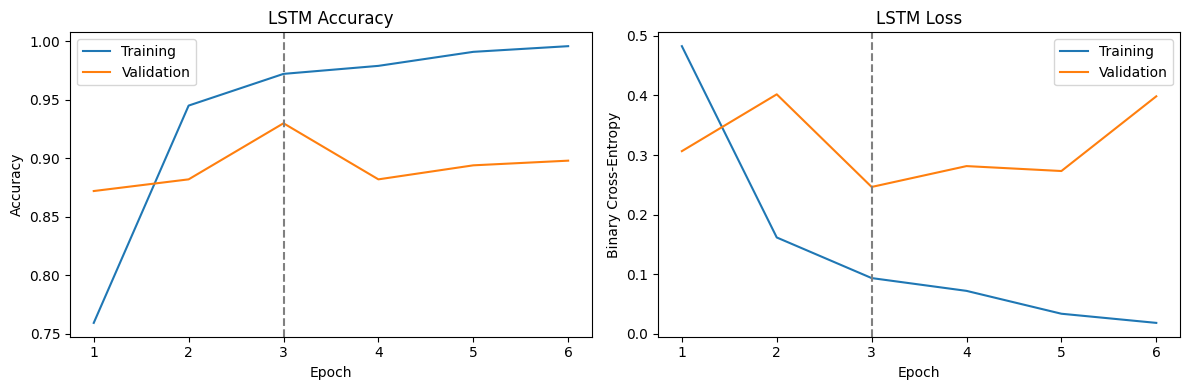

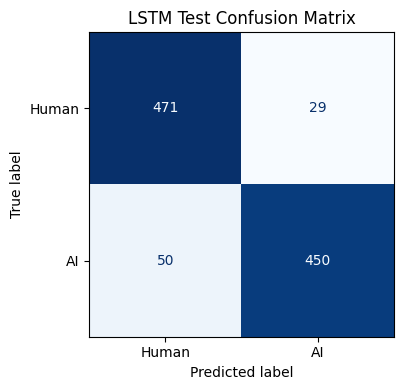

In [60]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Training and validation curves
epochs = range(1, len(history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history.history["accuracy"], label="Training")
axes[0].plot(epochs, history.history["val_accuracy"], label="Validation")
axes[0].set_title("LSTM Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(epochs, history.history["loss"], label="Training")
axes[1].plot(epochs, history.history["val_loss"], label="Validation")
axes[1].set_title("LSTM Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy")
axes[1].legend()

for ax in axes:
    ax.axvline(
        best_epoch,
        color="gray",
        linestyle="--",
        label=None
    )
    ax.set_xticks(list(epochs))

plt.tight_layout()
plt.savefig("lstm_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Test confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Human", "AI"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("LSTM Test Confusion Matrix")
plt.tight_layout()
plt.savefig("lstm_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [61]:
import json
import zipfile
from pathlib import Path
from sklearn.metrics import classification_report
from google.colab import files

# Save a complete model that accepts raw text.
# This includes the trained text vectorizer and LSTM.
text_input = tf.keras.Input(shape=(), dtype=tf.string, name="text")
output = lstm_model(vectorizer(text_input))

complete_model = tf.keras.Model(
    inputs=text_input,
    outputs=output
)

complete_model.save("lstm_text_detector.keras")

# Save the vocabulary separately for inspection.
with open("lstm_vocabulary.json", "w", encoding="utf-8") as f:
    json.dump(vectorizer.get_vocabulary(), f, ensure_ascii=False)

# Save actual measured results.
report = classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Human", "AI"],
    output_dict=True,
    zero_division=0
)

results = {
    "model": "Embedding + LSTM",
    "test_accuracy": float(test_accuracy),
    "macro_f1": float(report["macro avg"]["f1-score"]),
    "human_false_positive_rate": float(fp / (tn + fp)),
    "training_time_seconds": float(lstm_training_time),
    "epochs_completed": len(history.history["loss"]),
    "best_epoch": int(best_epoch),
    "train_samples": len(train_df),
    "validation_samples": len(val_df),
    "test_samples": len(test_df),
    "vocabulary_size": VOCAB_SIZE,
    "sequence_length": SEQUENCE_LENGTH,
    "embedding_dimensions": 64,
    "lstm_units": 64,
    "dropout": 0.5,
    "batch_size": 32,
    "learning_rate": 0.001,
    "classification_threshold": 0.5,
    "random_seed": 42,
    "tensorflow_version": tf.__version__
}

pd.DataFrame([results]).to_csv("lstm_results.csv", index=False)
pd.DataFrame(report).transpose().to_csv("lstm_classification_report.csv")

pd.DataFrame(history.history).rename_axis("epoch_index").to_csv(
    "lstm_training_history.csv"
)

# Save predictions for error analysis.
prediction_results = test_df.copy()
prediction_results["ai_probability"] = test_probabilities
prediction_results["predicted_label"] = test_predictions
prediction_results.to_csv("lstm_test_predictions.csv", index=False)

# Bundle the deliverables.
deliverables = [
    "lstm_text_detector.keras",
    "lstm_vocabulary.json",
    "lstm_results.csv",
    "lstm_classification_report.csv",
    "lstm_training_history.csv",
    "lstm_test_predictions.csv",
    "lstm_training_curves.png",
    "lstm_confusion_matrix.png"
]

missing = [name for name in deliverables if not Path(name).is_file()]
if missing:
    raise FileNotFoundError(f"Missing files: {missing}")

with zipfile.ZipFile(
    "Member_3_LSTM_Results.zip",
    "w",
    compression=zipfile.ZIP_DEFLATED
) as bundle:
    for filename in deliverables:
        bundle.write(filename)

files.download("Member_3_LSTM_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>